In [1]:
import pandas as pd
import matplotlib.pylab as plt
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score


In [2]:
df_clean = pd.read_csv('../data/processed/card_profiler_clean.csv')


In [3]:
df_prepare_clustering = pd.read_csv('../data/PCA/card_profiler_clustering.csv')


In [4]:
X_full = df_prepare_clustering.values

rows = []
for n in range(2, 6):
    X = X_full[:, :n]
    for k in range(2, 8):
        km = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = km.fit_predict(X)

        sil = silhouette_score(X, labels)
        inertia = km.inertia_
        min_share = np.bincount(labels).min() / len(labels)

        rows.append({
            "n_components": n,
            "k": k,
            "silhouette": sil,
            "inertia": inertia,
            "min_share": min_share,
        })

res = pd.DataFrame(rows)
res

,n_components,k,silhouette,inertia,min_share
0,2,2,0.430953,23542.395938,0.312884
1,2,3,0.448740,13244.219895,0.271315
2,2,4,0.421660,10414.983259,0.193429
3,2,5,0.410122,8242.980510,0.156442
4,2,6,0.394669,6689.621477,0.118672
5,2,7,0.397941,5634.987347,0.110068
6,3,2,0.368307,30681.084633,0.311990
7,3,3,0.382649,20205.727848,0.267181
8,3,4,0.388787,16448.250736,0.209297
9,3,5,0.390872,13781.047480,0.157895


K-means choice: 2 components, k = 3
cluster_kmeans
1    0.379
2    0.350
0    0.271
Name: proportion, dtype: float64
[[-0.45723567 -2.34342962]
 [-2.10059811  2.18851342]
 [ 0.82944242  0.71443488]
 ...
 [-0.42515092 -2.79352145]
 [-2.79325552 -2.63839822]
 [-0.28789299 -0.77241941]]
[[-0.45723567 -2.34342962 -0.5741327 ]
 [-2.10059811  2.18851342 -0.56180469]
 [ 0.82944242  0.71443488  1.569019  ]
 ...
 [-0.42515092 -2.79352145 -0.43599724]
 [-2.79325552 -2.63839822  0.48553998]
 [-0.28789299 -0.77241941  2.0123697 ]]
[[-0.45723567 -2.34342962 -0.5741327  -0.42590426]
 [-2.10059811  2.18851342 -0.56180469  0.61649506]
 [ 0.82944242  0.71443488  1.569019    0.51761813]
 ...
 [-0.42515092 -2.79352145 -0.43599724 -0.25590011]
 [-2.79325552 -2.63839822  0.48553998 -0.69373605]
 [-0.28789299 -0.77241941  2.0123697  -1.10385046]]
[[-0.45723567 -2.34342962 -0.5741327  -0.42590426  0.11900455]
 [-2.10059811  2.18851342 -0.56180469  0.61649506  0.55032085]
 [ 0.82944242  0.71443488  1.569019  

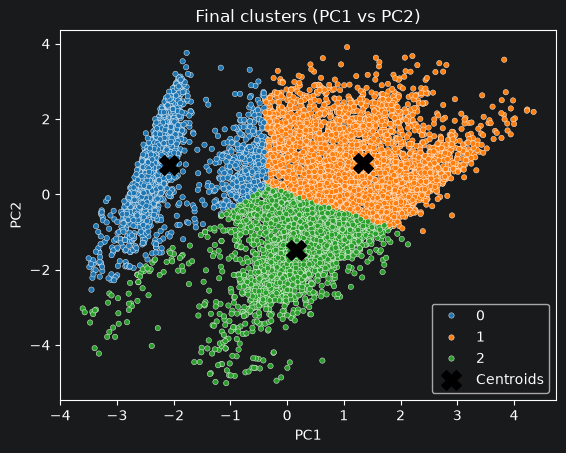

In [5]:
good = res[res["min_share"] >= 0.10]
best = good.sort_values("silhouette", ascending=False).iloc[0]
BEST_N = int(best["n_components"])
BEST_K = int(best["k"])
print("K-means choice:", BEST_N, "components, k =", BEST_K)

X_km = X_full[:, :BEST_N]
km = KMeans(n_clusters=BEST_K, n_init=10, random_state=42)
km.fit(X_km)

df_clean["cluster_kmeans"] = km.labels_
print(df_clean["cluster_kmeans"].value_counts(normalize=True).round(3))

rows = []
for n in range(2, 6):
    X = X_full[:, :n]
    print(X_full[:, :n])
    for eps in [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
        for ms in [5, 10, 20, 30]:
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)

            noise = (labels == -1).mean()
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

            if n_clusters >= 2:
                mask = labels != -1
                sil = silhouette_score(X[mask], labels[mask])
            else:
                sil = np.nan

            rows.append({
                "n_components": n,
                "eps": eps,
                "min_samples": ms,
                "silhouette": sil,
                "n_clusters": n_clusters,
                "noise_share": noise,
            })

res_db = pd.DataFrame(rows)
res_db = res_db.dropna().sort_values("silhouette", ascending=False)
res_db.head()

best_db = res_db.iloc[0]
DB_N = int(best_db["n_components"])
X_db = X_full[:, :DB_N]
db = DBSCAN(eps=best_db["eps"], min_samples=int(best_db["min_samples"]))
db_labels = db.fit_predict(X_db)

df_clean["cluster_dbscan"] = db_labels
df_clean["est_atypique_dbscan"] = df_clean["cluster_dbscan"] == -1
print(df_clean["cluster_dbscan"].value_counts(normalize=True).round(3))

mask = db_labels != -1

comparison = pd.DataFrame({
    "silhouette": [
        silhouette_score(X_km, km.labels_),
        silhouette_score(X_db[mask], db_labels[mask]),
    ],
    "davies_bouldin": [
        davies_bouldin_score(X_km, km.labels_),
        davies_bouldin_score(X_db[mask], db_labels[mask]),
    ],
    "calinski_harabasz": [
        calinski_harabasz_score(X_km, km.labels_),
        calinski_harabasz_score(X_db[mask], db_labels[mask]),
    ],
    "noise_%": [0, (db_labels == -1).mean() * 100],
    "min_cluster_%": [
        df_clean["cluster_kmeans"].value_counts(normalize=True).min() * 100,
        df_clean.loc[mask, "cluster_dbscan"].value_counts(normalize=True).min() * 100,
    ],
    "max_cluster_%": [
        df_clean["cluster_kmeans"].value_counts(normalize=True).max() * 100,
        df_clean.loc[mask, "cluster_dbscan"].value_counts(normalize=True).max() * 100,
    ],
}, index=["K-means", "DBSCAN"]).round(3)

print(comparison)

km_sil = comparison.loc["K-means", "silhouette"]
db_sil = comparison.loc["DBSCAN", "silhouette"]
db_noise = comparison.loc["DBSCAN", "noise_%"]

if db_sil > km_sil + 0.05 and db_noise < 5:
    df_clean["cluster_final"] = df_clean["cluster_dbscan"]
    print("Chosen method: DBSCAN")
else:
    df_clean["cluster_final"] = df_clean["cluster_kmeans"]
    print("Chosen method: K-means")

sns.scatterplot(
    x=X_full[:, 0], y=X_full[:, 1],
    hue=df_clean["cluster_final"], palette="tab10", s=15
)
plt.scatter(
    km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
    c="black", marker="X", s=200, label="Centroids"
)
plt.title("Final clusters (PC1 vs PC2)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

                Unnamed: 0  BALANCE  PURCHASES  ONEOFF_PURCHASES  \
cluster_kmeans                                                     
0                     0.03     0.29      -0.46             -0.35   
1                    -0.31     0.34       0.56              0.49   
2                     0.32    -0.59      -0.25             -0.27   

                INSTALLMENTS_PURCHASES  CASH_ADVANCE  CREDIT_LIMIT  PAYMENTS  
cluster_kmeans                                                                
0                                -0.45          0.49         -0.14     -0.04  
1                                 0.42          0.06          0.56      0.40  
2                                -0.10         -0.44         -0.50     -0.41  
                Unnamed: 0  BALANCE  PURCHASES  ONEOFF_PURCHASES  \
cluster_kmeans                                                     
0                   4546.0   2176.5       23.8              19.0   
1                   3672.7   2264.0     2198.8            14

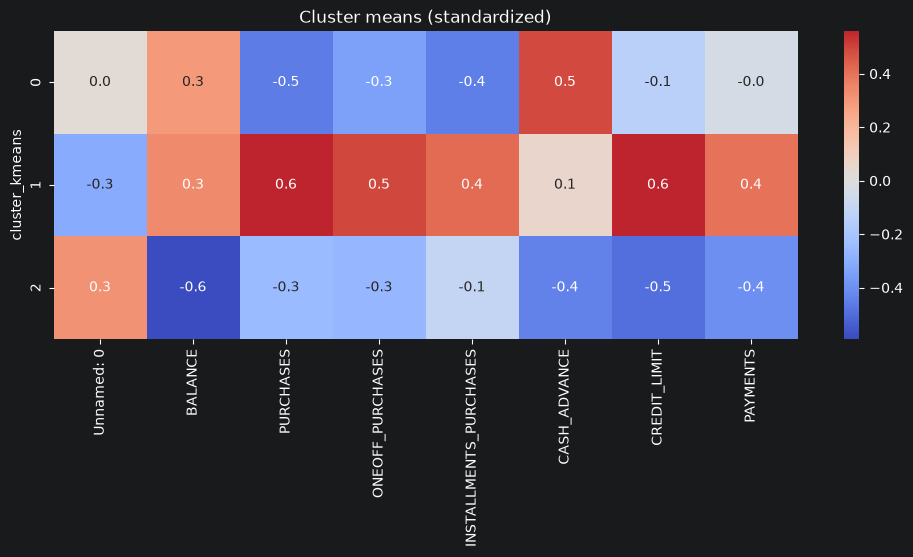

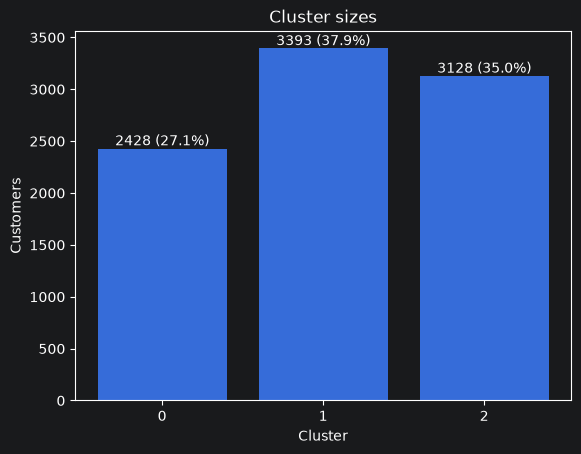

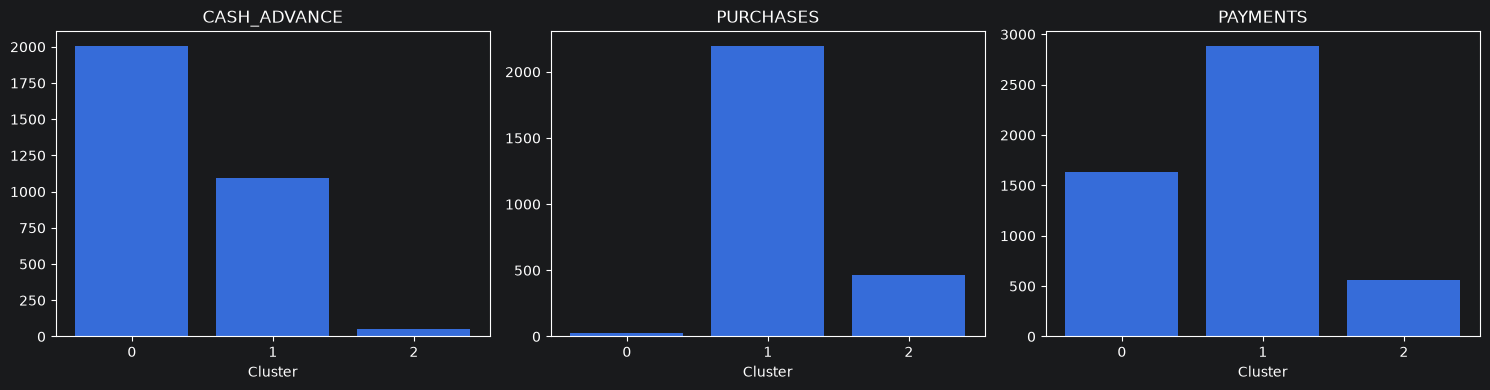

In [6]:

cluster_cols = ["cluster_kmeans", "cluster_dbscan", "est_atypique_dbscan", "cluster_final"]
num_cols = [c for c in df_clean.select_dtypes("number").columns if c not in cluster_cols]

df_std = (df_clean[num_cols] - df_clean[num_cols].mean()) / df_clean[num_cols].std()
df_std["cluster_kmeans"] = df_clean["cluster_kmeans"]

means_std = df_std.groupby("cluster_kmeans").mean()
print(means_std.round(2))

means_real = df_clean.groupby("cluster_kmeans")[num_cols].mean()
print(means_real.round(1))

plt.figure(figsize=(12, 4))
sns.heatmap(means_std, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Cluster means (standardized)")
plt.show()

sizes = df_clean["cluster_kmeans"].value_counts().sort_index()
pct = sizes / len(df_clean) * 100

plt.bar(sizes.index.astype(str), sizes.values)
for i in range(len(sizes)):
    plt.text(i, sizes.values[i], f"{sizes.values[i]} ({pct.values[i]:.1f}%)", ha="center", va="bottom")
plt.title("Cluster sizes")
plt.xlabel("Cluster")
plt.ylabel("Customers")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ["CASH_ADVANCE", "PURCHASES", "PAYMENTS"]):
    ax.bar(means_real.index.astype(str), means_real[var])
    ax.set_title(var)
    ax.set_xlabel("Cluster")
plt.tight_layout()
plt.show()

In [23]:
names = {
    0: "Premium Customers",
    1: "Low-Activity Customers",
    2: "At-Risk Customers",
}

df_clean["target"] = df_clean["cluster_kmeans"].map(names)

print(df_clean["target"].isna().sum())

compare = pd.DataFrame({
    "original_clusters_%": df_clean["cluster_kmeans"].value_counts(normalize=True).sort_index() * 100,
    "target_%": df_clean["target"].value_counts(normalize=True).rename(
        index={v: k for k, v in names.items()}).sort_index() * 100,
})
print(compare.round(1))
df_clean.to_csv('../data/processed/card_profiler_clean.csv')


0
   original_clusters_%  target_%
0                 27.1      27.1
1                 37.9      37.9
2                 35.0      35.0
